# 119 · Success-rate statistics: a success rate is a draw from a distribution

In [1]:
import numpy as np, matplotlib.pyplot as plt
from scipy.stats import norm, binom
from vlacourse import wilson

def wald(k, n, conf=0.95):
    z = norm.ppf(1 - (1 - conf) / 2); p = k / n; h = z * np.sqrt(p * (1 - p) / n)
    return p - h, p + h

def coverage(interval, p, n, trials=20000, seed=0):
    k = np.random.default_rng(seed).binomial(n, p, trials)
    lo_hi = np.array([interval(ki, n) for ki in range(n + 1)])
    return np.mean((lo_hi[k, 0] <= p) & (p <= lo_hi[k, 1]))

In [2]:
true_p, n = 0.75, 25
rng = np.random.default_rng(0)
seeds = rng.binomial(n, true_p, 5)
print("five seeds of the SAME policy (true success 0.75, 25 episodes each):", [f"{k}/{n}" for k in seeds])
for k in seeds:
    print(f"  {k}/{n} = {k / n:.0%}   Wilson 95% CI [{wilson(k, n)[0]:.0%}, {wilson(k, n)[1]:.0%}]")
K, N = seeds.sum(), n * len(seeds)
print(f"pooled {K}/{N} = {K / N:.0%}  CI [{wilson(K, N)[0]:.0%}, {wilson(K, N)[1]:.0%}]  (width shrinks like 1/sqrt(n))")

five seeds of the SAME policy (true success 0.75, 25 episodes each): ['18/25', '20/25', '22/25', '23/25', '17/25']
  18/25 = 72%   Wilson 95% CI [52%, 86%]
  20/25 = 80%   Wilson 95% CI [61%, 91%]
  22/25 = 88%   Wilson 95% CI [70%, 96%]
  23/25 = 92%   Wilson 95% CI [75%, 98%]
  17/25 = 68%   Wilson 95% CI [48%, 83%]
pooled 100/125 = 80%  CI [72%, 86%]  (width shrinks like 1/sqrt(n))


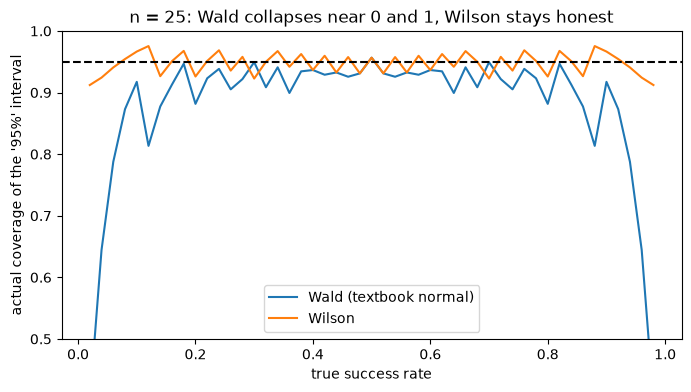

Wald interval for 25/25 successes: (np.float64(1.0), np.float64(1.0))   <- zero width, absurd;  Wilson: [0.867 1.   ]


In [3]:
ps = np.linspace(0.02, 0.98, 49)
plt.figure(figsize=(8, 4))
for name, f in [("Wald (textbook normal)", wald), ("Wilson", wilson)]:
    plt.plot(ps, [coverage(f, p, 25) for p in ps], label=name)
plt.axhline(0.95, c="k", ls="--"); plt.ylim(0.5, 1.0); plt.xlabel("true success rate"); plt.ylabel("actual coverage of the '95%' interval")
plt.title("n = 25: Wald collapses near 0 and 1, Wilson stays honest"); plt.legend(); plt.show()
print("Wald interval for 25/25 successes:", wald(25, 25), "  <- zero width, absurd;  Wilson:", np.round(wilson(25, 25), 3))

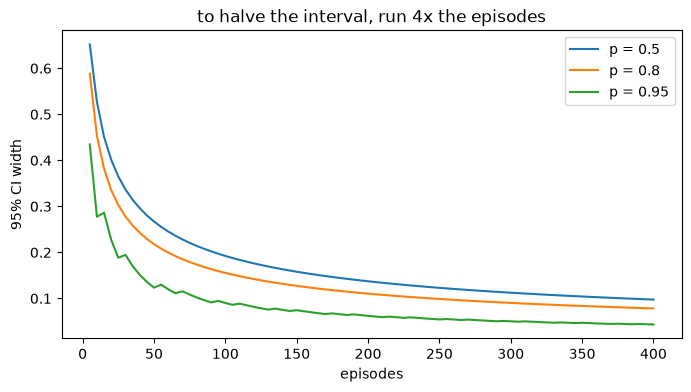

70% measured with n= 10: CI [0.40, 0.89]  width 0.50
70% measured with n= 25: CI [0.48, 0.83]  width 0.34
70% measured with n= 50: CI [0.56, 0.81]  width 0.25
70% measured with n=100: CI [0.60, 0.78]  width 0.18
70% measured with n=200: CI [0.63, 0.76]  width 0.13


In [4]:
ns = np.arange(5, 401, 5)
plt.figure(figsize=(8, 4))
for p in [0.5, 0.8, 0.95]:
    plt.plot(ns, [wilson(int(round(p * n)), n)[1] - wilson(int(round(p * n)), n)[0] for n in ns], label=f"p = {p}")
plt.xlabel("episodes"); plt.ylabel("95% CI width"); plt.legend(); plt.title("to halve the interval, run 4x the episodes"); plt.show()
for n in [10, 25, 50, 100, 200]:
    lo, hi = wilson(int(0.7 * n), n)
    print(f"70% measured with n={n:3d}: CI [{lo:.2f}, {hi:.2f}]  width {hi - lo:.2f}")